Install and import libraries

In [1]:
!pip install -q librosa vaderSentiment soundfile

import os, subprocess, warnings
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")

Cell 2a: Download the MELD dataset
# CELL 2a: Download the raw MELD dataset (~11 GB) directly into Colab storage

In [11]:
import os
os.makedirs('/content/MELD', exist_ok=True)

# 1. Raw data Hugging Face (~11 GB)
!wget --show-progress -c https://huggingface.co/datasets/declare-lab/MELD/resolve/main/MELD.Raw.tar.gz -O /content/MELD/MELD.Raw.tar.gz

# 2. Checking size (size ~10-11 GB )
!ls -lh /content/MELD

--2026-10-25 13:21:39--  https://huggingface.co/datasets/declare-lab/MELD/resolve/main/MELD.Raw.tar.gz
Resolving huggingface.co (huggingface.co)... 18.239.50.80, 18.239.50.16, 18.239.50.103, ...
Connecting to huggingface.co (huggingface.co)|18.239.50.80|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/6356101360c1b72f626ab49f/714191188117577a467426e969011bbee103072d7364b6b6737423128204e197?response-content-disposition=inline%3B+filename*%3DUTF-8%27%27MELD.Raw.tar.gz%3B+filename%3D%22MELD.Raw.tar.gz%22%3B&user_id=public&X-Xet-Cas-Uid=public&response-content-type=application%2Fgzip&xip=RU63Uv9jJdc&Expires=1792938099&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjM1NjEwMTM2MGMxYjcyZjYyNmFiNDlmLzcxNDE5MTE4ODExNzU3N2E0Njc0MjZlOTY5MDExYmJlZTEwMzA3MmQ3MzY0YjZiNjczNzQyMzEyODIwNGUxOTdcXD9yZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSomdXNlcl9pZD1wdWJsaWMmWC1YZXQtQ2FzLVVpZD1wdWJsaWMmcm

Cell 2b: Extract the data and set paths
# CELL 2b: Extract the dataset, download the CSV and set file paths

In [14]:

!find /content/MELD -maxdepth 3 -name "*.csv"
!ls /content/MELD
!ls /content/MELD/train_splits | head

MELD.Raw.tar.gz  train_splits


In [15]:
import os
!wget -q https://raw.githubusercontent.com/declare-lab/MELD/master/data/MELD/train_sent_emo.csv -O /content/MELD/train_sent_emo.csv

CSV_PATH  = '/content/MELD/train_sent_emo.csv'
VIDEO_DIR = '/content/MELD/train_splits'
WAV_DIR   = '/content/wav'
os.makedirs(WAV_DIR, exist_ok=True)

In [17]:
!ls -lh /content/MELD/MELD.Raw.tar.gz

-rw-r--r-- 1 root root 11G Oct 25 13:23 /content/MELD/MELD.Raw.tar.gz


In [18]:
!tar -xzf /content/MELD/MELD.Raw.tar.gz -C /content/MELD
!ls /content/MELD
!ls /content/MELD/MELD.Raw

MELD.Raw  MELD.Raw.tar.gz  train_sent_emo.csv  train_splits
dev_sent_emo.csv  README.txt	     test.tar.gz
dev.tar.gz	  test_sent_emo.csv  train.tar.gz


In [19]:
!tar -xzf /content/MELD/MELD.Raw/train.tar.gz -C /content/MELD/train_splits
!ls /content/MELD/train_splits | head

train_sent_emo.csv
train_splits


In [20]:
VIDEO_DIR = '/content/MELD/train_splits/train_splits'
!ls /content/MELD/train_splits/train_splits | head

dia0_utt0.mp4
dia0_utt10.mp4
dia0_utt11.mp4
dia0_utt12.mp4
dia0_utt13.mp4
dia0_utt1.mp4
dia0_utt2.mp4
dia0_utt3.mp4
dia0_utt4.mp4
dia0_utt5.mp4


Cell 3: Load data and create a balanced subset

In [22]:
# CELL 3: Load the CSV and build a small, balanced subset
# Load the annotation file (each row = one spoken sentence with its emotion label)
df = pd.read_csv(CSV_PATH)
print(df.shape)
print(df['Emotion'].value_counts())         # how many samples per emotion

# Build the video file path for every utterance (naming format: dia<ID>_utt<ID>.mp4)
df['video'] = df.apply(lambda r: f"{VIDEO_DIR}/dia{r.Dialogue_ID}_utt{r.Utterance_ID}.mp4", axis=1)
df = df[df['video'].apply(os.path.exists)].reset_index(drop=True)

# # Take at most 250 samples per emotion so the experiment runs fast and classes stay balanced
df = df.groupby('Emotion', group_keys=False).apply(lambda x: x.sample(min(len(x), 250), random_state=42)).reset_index(drop=True)
print("Subset size:", len(df))
df[['Utterance','Emotion']].head()

(9989, 11)
Emotion
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64
Subset size: 1750


,Utterance,Emotion
0,What?! What the hell?!,anger
1,Because I’m not going to spend one more day wi...,anger
2,Come on apartment! Come on apartment! Oh! I k...,anger
3,And-and that’s only ‘cause it’s right there wh...,anger
4,"No, no, no, don't! I've been waitin' for like,...",anger


Cell 4: Extract audio from the videos

In [23]:
# CELL 4: Extract the audio track from each video clip using ffmpeg
def extract_wav(video_path, wav_path):
    cmd = ['ffmpeg', '-y', '-i', video_path, '-vn', '-ac', '1', '-ar', '16000', wav_path, '-loglevel', 'quiet']
    subprocess.run(cmd)
    return os.path.exists(wav_path)     # True if the audio file was created

wav_paths = []
for i, row in df.iterrows():
    wav = f"{WAV_DIR}/{i}.wav"
    ok = extract_wav(row['video'], wav)
    wav_paths.append(wav if ok else None)
# Store audio paths in the dataframe and drop clips where extraction failed
df['wav'] = wav_paths
df = df.dropna(subset=['wav']).reset_index(drop=True)
print("Audio files ready:", len(df))

Audio files ready: 1750


Cell 5: Show the dataset and play audio

,Utterance,Emotion
1704,Both of us?,surprise
1694,"Oh, that's what she meant!",surprise
47,"Hey-hey, y’know what?",anger
304,That sucks!,disgust
534,Please? Please?! We just don't want to deal wi...,fear
1041,"Look, it’s like I told you, there’s nothing I ...",neutral
48,Damn! I can’t believe I took her off my list.,anger
1587,That was a half an hour?,surprise
302,"Yeah, this was a stupid idea.",disgust
1582,Hey! Look who I found!,surprise


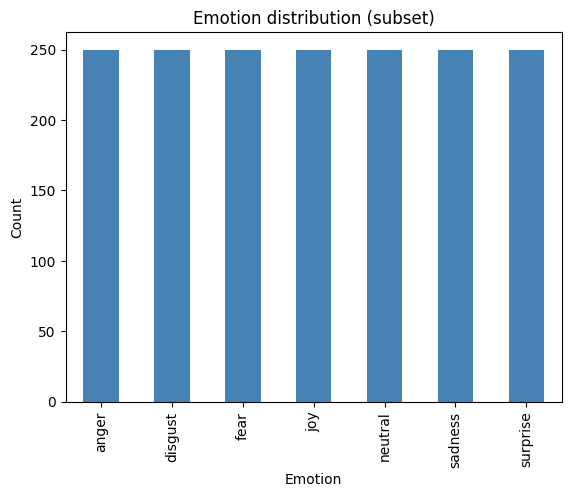


Emotion: joy
Text   : Noooo!  I'm lying. I am so drunk.



Emotion: anger
Text   : What?!  What the hell?!



Emotion: sadness
Text   : Ohh, the-the Foster puppets!


In [33]:
import IPython.display as ipd

# 1. Show 10 random samples from the dataset (text + emotion label)
display(df[['Utterance', 'Emotion']].sample(10, random_state=1))

# 2. Plot how many samples each emotion has in our subset
df['Emotion'].value_counts().plot(kind='bar', color='steelblue', title='Emotion distribution (subset)')
plt.ylabel('Count'); plt.show()

# 3. Show text and play audio for three different emotions
for emo in ['joy', 'anger', 'sadness']:
    row = df[df['Emotion'] == emo].iloc[0]
    print(f"\nEmotion: {emo}")
    print("Text   :", row['Utterance'])
    ipd.display(ipd.Audio(row['wav']))   # play button for the audio clip

Cell 6: Audio feature extraction

In [24]:
# CELL 6: Extract audio features (pitch, tone, energy) from every clip
def audio_features(path):
    y, sr = librosa.load(path, sr=16000)                             # load audio signal
    mfcc   = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)             # MFCC: captures voice tone/timbre
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)                 # chroma: pitch-class content
    zcr    = librosa.feature.zero_crossing_rate(y)                   # zero crossing rate: noisiness
    rms    = librosa.feature.rms(y=y)                                # RMS: loudness/energy
    cent   = librosa.feature.spectral_centroid(y=y, sr=sr)           # spectral centroid: brightness of sound
    f0     = librosa.yin(y, fmin=50, fmax=400, sr=sr)   # pitch

# Summarise each feature over time using mean/std so every clip gives a fixed-length vector
    return np.hstack([
        mfcc.mean(axis=1), mfcc.std(axis=1),
        chroma.mean(axis=1),
        zcr.mean(), rms.mean(), cent.mean(),
        f0.mean(), f0.std(), f0.max() - f0.min()
    ])

# Build the audio feature matrix: one row per clip
X_audio = np.array([audio_features(p) for p in df['wav']])
print("Audio feature shape:", X_audio.shape)

Audio feature shape: (1750, 98)


Cell 7: Label encoding and train/test split

In [25]:
# CELL 7: Convert emotion names to numbers and split the data into train and test sets
le = LabelEncoder()
y = le.fit_transform(df['Emotion'])
print(dict(zip(le.classes_, range(len(le.classes_)))))

idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=42)
y_train, y_test = y[idx_train], y[idx_test]

{'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'neutral': 4, 'sadness': 5, 'surprise': 6}


Cell 8: Text feature extraction

In [27]:
# CELL 8: Extract text features (sentiment analysis + TF-IDF)
analyzer = SentimentIntensityAnalyzer()

def sentiment_feats(text):
  # VADER gives negative, neutral, positive and compound sentiment scores
    s = analyzer.polarity_scores(str(text))
    return [s['neg'], s['neu'], s['pos'], s['compound']]

X_sent = np.array([sentiment_feats(t) for t in df['Utterance']])
# TF-IDF converts words into numbers based on how important they are
tfidf = TfidfVectorizer(max_features=300, stop_words='english')
tfidf.fit(df['Utterance'].iloc[idx_train])                      # learn vocabulary from training text only
X_tfidf = tfidf.transform(df['Utterance']).toarray()

# Final text features = sentiment scores + TF-IDF values
X_text = np.hstack([X_sent, X_tfidf])
print("Text feature shape:", X_text.shape)

Text feature shape: (1750, 304)


Cell 9: Combine text and audio (feature fusion)

In [28]:
# CELL 9: Combine text and audio features into one feature vector (feature-level fusion)
# Standardise audio features (mean 0, std 1) because they have very different scales
scaler = StandardScaler()
scaler.fit(X_audio[idx_train])                              # fit on training data only
X_audio_s = scaler.transform(X_audio)

# Join text and audio features side by side
X_fused = np.hstack([X_text, X_audio_s])
print("Fused feature shape:", X_fused.shape)

Fused feature shape: (1750, 402)


Cell 10: Train the classifier and compare modalities

In [29]:
# CELL 10: Train a Random Forest classifier on text only, audio only and text + audio
def train_eval(X, name):
    clf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced')
    clf.fit(X[idx_train], y_train)                           # train on the training set
    pred = clf.predict(X[idx_test])                          # predict on the unseen test set
    acc = accuracy_score(y_test, pred)
    print(f"{name:12s} accuracy: {acc:.3f}")
    return clf, pred, acc

_, _, acc_t = train_eval(X_text,    "Text only")            # model 1: text features only
_, _, acc_a = train_eval(X_audio_s, "Audio only")           # model 2: audio features only
clf, pred, acc_f = train_eval(X_fused, "Text+Audio")        # model 3: combined (final model)

Text only    accuracy: 0.274
Audio only   accuracy: 0.197
Text+Audio   accuracy: 0.263


In [35]:
# CELL 10b: Try Logistic Regression (usually better than Random Forest on text features)
from sklearn.linear_model import LogisticRegression

def run_lr(X, name, C=0.5):
    model = LogisticRegression(max_iter=3000, class_weight='balanced', C=C)
    model.fit(X[idx_train], y_train)
    p = model.predict(X[idx_test])
    acc = accuracy_score(y_test, p)
    print(f"{name:12s} accuracy: {acc:.3f}")
    return model, p, acc

_, _, acc_t = run_lr(X_text,    "Text only")
_, _, acc_a = run_lr(X_audio_s, "Audio only")
clf, pred, acc_f = run_lr(X_fused, "Text+Audio")

Text only    accuracy: 0.269
Audio only   accuracy: 0.200
Text+Audio   accuracy: 0.249


In [36]:
# CELL 10c: Better text features (sentence embeddings) + late fusion

!pip install -q sentence-transformers
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression

# Convert every sentence into a 384-number embedding that captures its meaning
st_model = SentenceTransformer('all-MiniLM-L6-v2')
X_emb = st_model.encode(df['Utterance'].astype(str).tolist(), batch_size=64, show_progress_bar=True)
X_text2 = np.hstack([X_sent, X_emb])                 # sentiment scores + embeddings

def fit_lr(X, C):
    m = LogisticRegression(max_iter=3000, class_weight='balanced', C=C)
    m.fit(X[idx_train], y_train)
    return m

# Separate models for text and audio
m_text  = fit_lr(X_text2,   C=0.5)
m_audio = fit_lr(X_audio_s, C=0.1)
p_text  = m_text.predict_proba(X_text2[idx_test])
p_audio = m_audio.predict_proba(X_audio_s[idx_test])

# Late fusion: average the probabilities of the two models (equal weights)
p_late = 0.5 * p_text + 0.5 * p_audio

# Early fusion with the new text features (for comparison)
m_early = fit_lr(np.hstack([X_text2, X_audio_s]), C=0.2)
p_early = m_early.predict(np.hstack([X_text2, X_audio_s])[idx_test])

print(f"Text only (embeddings) : {accuracy_score(y_test, p_text.argmax(1)):.3f}")
print(f"Audio only             : {accuracy_score(y_test, p_audio.argmax(1)):.3f}")
print(f"Early fusion           : {accuracy_score(y_test, p_early):.3f}")
print(f"Late fusion (text+audio): {accuracy_score(y_test, p_late.argmax(1)):.3f}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/28 [00:00<?, ?it/s]

Text only (embeddings) : 0.400
Audio only             : 0.197
Early fusion           : 0.311
Late fusion (text+audio): 0.343


Cell 11: Results, confusion matrix and comparison chart

Text weight used in late fusion: 0.5
Text only 0.400 | Audio only 0.197 | Early fusion 0.311 | Late fusion 0.343

              precision    recall  f1-score   support

       anger       0.22      0.16      0.19        50
     disgust       0.33      0.40      0.36        50
        fear       0.26      0.18      0.21        50
         joy       0.46      0.56      0.50        50
     neutral       0.40      0.44      0.42        50
     sadness       0.34      0.32      0.33        50
    surprise       0.30      0.34      0.32        50

    accuracy                           0.34       350
   macro avg       0.33      0.34      0.33       350
weighted avg       0.33      0.34      0.33       350



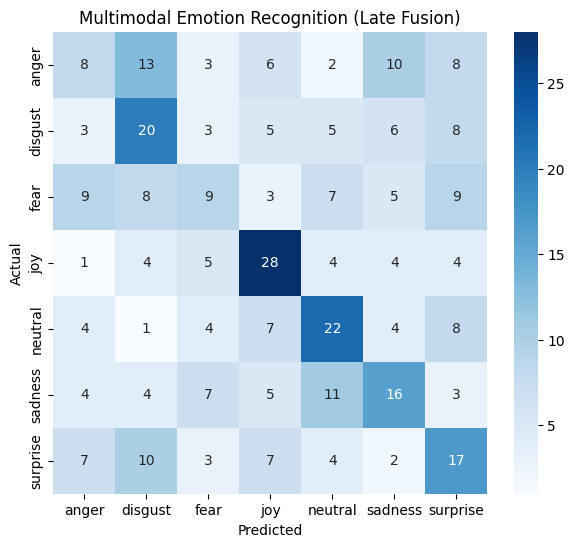

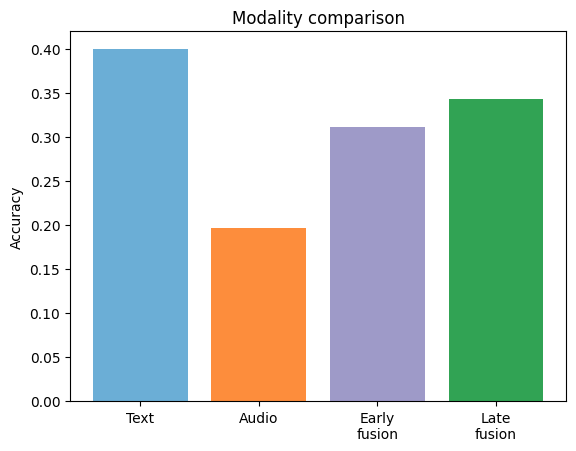

In [37]:
# CELL 11: Evaluate the final text + audio (late fusion) model and visualise results

# Use the tuned text weight from Cell 10d if it was run, otherwise equal weights
W = best_w if 'best_w' in globals() else 0.5
p_final    = W * p_text + (1 - W) * p_audio           # weighted average of the two probability outputs
pred_final = p_final.argmax(1)

# Accuracy of every approach on the same test set
acc_text  = accuracy_score(y_test, p_text.argmax(1))
acc_audio = accuracy_score(y_test, p_audio.argmax(1))
acc_early = accuracy_score(y_test, p_early)
acc_late  = accuracy_score(y_test, pred_final)
print(f"Text weight used in late fusion: {W}")
print(f"Text only {acc_text:.3f} | Audio only {acc_audio:.3f} | Early fusion {acc_early:.3f} | Late fusion {acc_late:.3f}\n")

# Precision, recall and F1-score for every emotion
print(classification_report(y_test, pred_final, target_names=le.classes_))

# Confusion matrix: shows which emotions get confused with each other
cm = confusion_matrix(y_test, pred_final)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Multimodal Emotion Recognition (Late Fusion)')
plt.show()

# Bar chart comparing all approaches
plt.bar(['Text', 'Audio', 'Early\nfusion', 'Late\nfusion'], [acc_text, acc_audio, acc_early, acc_late],
        color=['#6baed6', '#fd8d3c', '#9e9ac8', '#31a354'])
plt.ylabel('Accuracy'); plt.title('Modality comparison'); plt.show()

Cell 12: Predict emotion for new samples

In [38]:
# CELL 12: Predict the emotion of one sample using text + audio

def predict_emotion(text, wav_path):
    # Text features: VADER sentiment + sentence embedding
    t = np.hstack([sentiment_feats(text), st_model.encode([str(text)])[0]])
    # Audio features: scaled pitch/MFCC/energy features
    a = scaler.transform([audio_features(wav_path)])[0]
    # Late fusion: weighted average of the text-model and audio-model probabilities
    p = W * m_text.predict_proba([t]) + (1 - W) * m_audio.predict_proba([a])
    return le.classes_[p.argmax()]

# Try it on the first test sample
i = idx_test[0]
print("Text:", df['Utterance'][i])
print("Actual:", df['Emotion'][i], "| Predicted:", predict_emotion(df['Utterance'][i], df['wav'][i]))

Text: Why not?
Actual: neutral | Predicted: surprise


Cell 13: Sample Input / Sample Output

SAMPLE INPUT
Text: Well hey, I’ve got a ton of these!
Audio clip:



SAMPLE OUTPUT
VADER sentiment (neg, neu, pos, compound): [0.    0.745 0.255 0.338]
Text Features Shape: (388,)


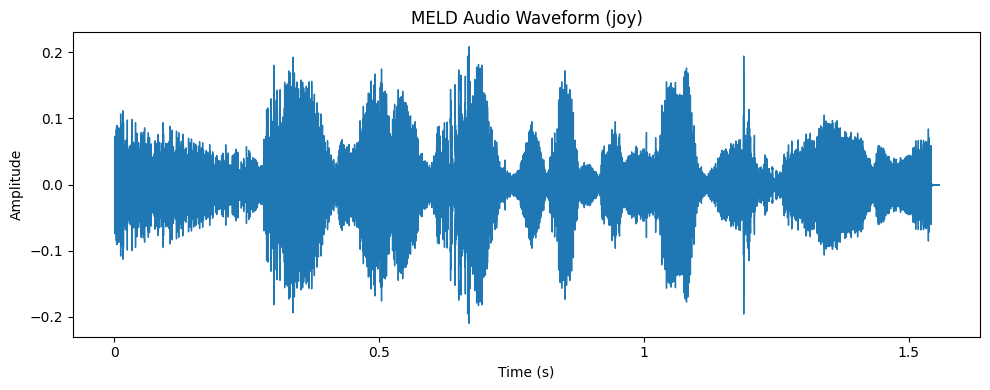

Mean pitch (Hz): 282.8 | Energy (RMS): 0.0361
Audio Features Shape: (98,)
Combined Features Shape: (486,)
Model trained on text + audio features.

Actual Emotion   : joy
Predicted Emotion: joy


In [39]:
# CELL 13: Show sample input and output in the lab manual format

# Pick one "joy" sample from the test set (similar to the "happy" example in the manual)
i = [k for k in idx_test if df['Emotion'][k] == 'joy'][0]
text, wav = df['Utterance'][i], df['wav'][i]

print("SAMPLE INPUT")
print("Text:", text)
print("Audio clip:")
ipd.display(ipd.Audio(wav))

# Extract text features (sentiment + sentence embedding) and audio features (scaled)
t_feat = np.hstack([sentiment_feats(text), st_model.encode([str(text)])[0]])
a_raw  = audio_features(wav)
a_feat = scaler.transform([a_raw])[0]

# Combined feature vector (text + audio side by side)
comb = np.hstack([t_feat, a_feat])

print("\nSAMPLE OUTPUT")
print("VADER sentiment (neg, neu, pos, compound):", np.round(sentiment_feats(text), 3))
print("Text Features Shape:", t_feat.shape)

# Plot the audio waveform
y_, sr_ = librosa.load(wav, sr=16000)
plt.figure(figsize=(10, 4))
librosa.display.waveshow(y_, sr=sr_)
plt.title("MELD Audio Waveform (" + df['Emotion'][i] + ")")
plt.xlabel("Time (s)"); plt.ylabel("Amplitude")
plt.tight_layout(); plt.show()

# Print key audio values: mean pitch and energy (RMS) from the raw features
print("Mean pitch (Hz):", round(a_raw[-3], 1), "| Energy (RMS):", round(a_raw[-5], 4))
print("Audio Features Shape:", a_feat.shape)
print("Combined Features Shape:", comb.shape)
print("Model trained on text + audio features.")

# Compare the final model's prediction with the true label
print("\nActual Emotion   :", df['Emotion'][i])
print("Predicted Emotion:", predict_emotion(text, wav))

CELL 14: Show test samples where the model's prediction is WRONG


In [40]:

# Find test samples where predicted emotion != actual emotion
wrong = [k for k, p in zip(idx_test, pred_final) if le.classes_[p] != df['Emotion'][k]]
print(f"Wrong predictions: {len(wrong)} out of {len(idx_test)} test samples")

# Show the first 3 wrong samples with their audio
for k in wrong[:3]:
    print("\n" + "-" * 40)
    print("Text     :", df['Utterance'][k])
    print("Actual   :", df['Emotion'][k])
    print("Predicted:", predict_emotion(df['Utterance'][k], df['wav'][k]))
    ipd.display(ipd.Audio(df['wav'][k]))      # play the audio clip

Wrong predictions: 230 out of 350 test samples

----------------------------------------
Text     : Why not?
Actual   : neutral
Predicted: surprise



----------------------------------------
Text     : We've got the ground-up flesh of formerly cute cows and turkeys, ew...
Actual   : disgust
Predicted: sadness



----------------------------------------
Text     : Hey, hang up! You get food poisoning just talkin’ to that place.
Actual   : disgust
Predicted: fear


Created by Areeba Khanam